# Final stacker: three inputs

The stacker combines three inputs, all fitted or scored without the stacker set's labels:
1. **Encoder v2**: BGE-M3 (XLM-R large, 8k positions) fine-tuned on 100k whole texts (`encoder/long_encoder.py`), one prediction per text instead of Branch A's mean over 512-token windows.
2. **Curve statistics**: the window detector's p(AI) curves at 64 / 128 / 256 tokens, as in `curve_stacker.ipynb` (job 3016350).
3. **Qwen3-8B log-probabilities**: per-token log-prob and entropy of an open LLM (`encoder/qwen_logprobs.py`, no training), turned into curves by a calibration fitted on the detector set, plus whole-text statistics.

Same protocol as `curve_stacker.ipynb`: model choice by 5-fold CV on the stacker set, class weights tuned on out-of-fold probabilities, validation (fold 0) scored once per configuration. References: R0 = Branch A (0.9023) and the previous final model E2 = Branch A + curves (0.9344).

In [1]:
import json
import pickle
import sys
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, roc_auc_score
from sklearn.model_selection import ParameterGrid
from tqdm.auto import tqdm

sys.path.insert(0, str(Path("../cluster").resolve()))
from encoder.curve_features import curve_features
from encoder.data import LABELS, SEED, load_sets
from encoder.qwen_features import fit_calibration, text_stats, windows, with_p_ai
from encoder.stacking import (apply_weights, bootstrap_diff, in_label_order, log_probs, make_model, make_submission,
                              oof_probs, read_parts, score, to_labels, tune_weights)

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"
CURVES_JOB, ENCODER_JOB, QWEN_JOB = "3016350", "3017270", "3017273"
RESULTS = Path("../cluster/results")
CACHE = Path("../outputs/final")  # features and CV runs (recomputing takes minutes)
CACHE.mkdir(parents=True, exist_ok=True)
SETS = ["stacker", "val", "test"]
QWEN_SIZES = [64, 128, 256]

sets = load_sets(kagglehub.competition_download(COMPETITION))
y = {name: sets[name]["label"].to_numpy() for name in ("stacker", "val")}
pd.DataFrame({"texts": {name: len(df) for name, df in sets.items()}}).T

,detector,stacker,encoder,val,test
texts,34638,29999,100001,27236,25000


## 1. Encoder v2 alone
Encoder v2's training summary and loss, and its validation score on its own (argmax, no stacker) next to Branch A's. Both sets of probabilities come from the cluster.

In [2]:
def probs_of(job, pattern, set_name):
    """Text probabilities (LABELS columns) of one set from a cluster job, in the set's row order."""
    return read_parts(RESULTS / job, pattern.format(set_name)).set_index("id").loc[sets[set_name]["id"], LABELS]


probs = {"branch_a": {s: probs_of(CURVES_JOB, "branch_a_probs_{}.part*.csv", s) for s in SETS},
         "encoder_v2": {s: probs_of(ENCODER_JOB, "encoder_probs_{}.part*.csv", s) for s in SETS}}
encoder_run = json.loads((RESULTS / ENCODER_JOB / "encoder-v2.json").read_text())
pd.DataFrame({"R0: Branch A, argmax": score(y["val"], to_labels(probs["branch_a"]["val"])),
              "encoder v2, argmax": score(y["val"], to_labels(probs["encoder_v2"]["val"]))}).T.round(4)

,macro_f1,f1_human,f1_ai,f1_fusion
"R0: Branch A, argmax",0.9023,0.8368,0.9901,0.8801
"encoder v2, argmax",0.9587,0.9350,0.9947,0.9462


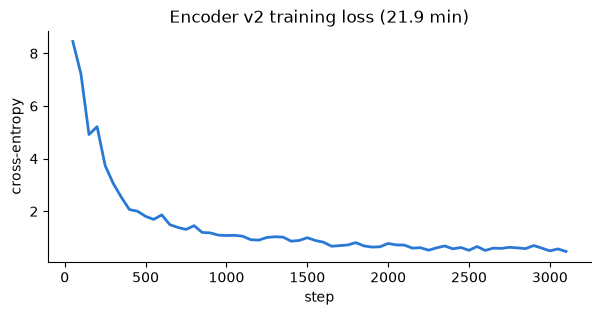

In [3]:
loss_log = pd.read_csv(RESULTS / ENCODER_JOB / "encoder-v2_loss.csv")
ax = loss_log.plot(x="step", y="loss", legend=False, figsize=(7, 3), color="#2a78d6", linewidth=2)
ax.set(title=f"Encoder v2 training loss ({encoder_run['train_minutes']} min)", xlabel="step", ylabel="cross-entropy")
ax.spines[["top", "right"]].set_visible(False);

## 2. Qwen features
From the 32-token chunk table: windows of 64 / 128 / 256 tokens every 32 tokens with their mean log-prob and entropy, a per-window p(AI) from a logistic regression fitted on **detector-set** windows only (human = 0, ai = 1), then the usual curve features (`encoder/curve_features.py`) per size, plus whole-text statistics. The diagnostic table shows how well each window size separates ai from human windows on the stacker set (held out from the calibration).

In [4]:
def qwen_chunks(set_name):
    """Qwen chunk table of one set."""
    return read_parts(RESULTS / QWEN_JOB, f"qwen_chunks_{set_name}.part*.csv.gz")


chunks = {s: qwen_chunks(s) for s in tqdm(["detector", *SETS], desc="Qwen chunks")}
window_tables = {(s, size): windows(chunks[s], size) for s in chunks for size in QWEN_SIZES}
detector_labels = sets["detector"].set_index("id")["label"]
calibrations = {size: fit_calibration(window_tables[("detector", size)], detector_labels, seed=SEED) for size in QWEN_SIZES}


def window_auc(set_name, size):
    """AUC of the calibrated p(AI) for windows of ai vs human texts of one set."""
    table = with_p_ai(window_tables[(set_name, size)], calibrations[size])
    label = table["id"].map(sets[set_name].set_index("id")["label"])
    pure = label.isin(["human", "ai"])
    return roc_auc_score(label[pure] == "ai", table.loc[pure, "p_ai"])


pd.DataFrame({f"{size} tokens": {"detector (fit)": window_auc("detector", size), "stacker (held out)": window_auc("stacker", size)}
              for size in QWEN_SIZES}).round(3)

Qwen chunks:   0%|          | 0/4 [00:00<?, ?it/s]

,64 tokens,128 tokens,256 tokens
detector (fit),0.850,0.876,0.893
stacker (held out),0.851,0.877,0.894


In [5]:
def qwen_features(set_name):
    """Qwen curve features at every size plus whole-text statistics, one row per text (cached as CSV)."""
    path = CACHE / f"qwen_features_{QWEN_JOB}_{set_name}.csv"
    if path.exists():
        return pd.read_csv(path, index_col="id")
    parts = [curve_features(with_p_ai(window_tables[(set_name, size)], calibrations[size])).add_prefix(f"qwen{size}__")
             for size in QWEN_SIZES]
    parts.append(text_stats(chunks[set_name]).add_prefix("qwen_text__"))
    features = pd.concat(parts, axis=1)
    features.index.name = "id"
    features.to_csv(path)
    return features


qwen = {s: qwen_features(s) for s in tqdm(SETS, desc="Qwen features")}
pair = sets["stacker"]["label"].isin(["human", "fusion"]).to_numpy()
text_auc = {column: roc_auc_score(y["stacker"][pair] == "fusion", qwen["stacker"].loc[sets["stacker"]["id"], column].to_numpy()[pair])
            for column in qwen["stacker"].columns if column.startswith("qwen_text__") or column.endswith("__mean")}
pd.Series(text_auc, name="AUC fusion vs human (stacker set)").round(3).to_frame()

Qwen features:   0%|          | 0/3 [00:00<?, ?it/s]

,AUC fusion vs human (stacker set)
qwen64__mean,0.614
qwen128__mean,0.614
qwen256__mean,0.603
qwen_text__mean_logp,0.596
qwen_text__mean_entropy,0.432
qwen_text__chunk_logp_std,0.601
qwen_text__logp_entropy_ratio,0.448


## 3. Experiments
Each configuration is a set of **inputs** × a model with its parameters. The inputs: `branch_a` (Branch A log-probabilities), `encoder_v2` (encoder v2 log-probabilities), `curves` (the E2 curve features: all sizes, fine stride, cross-scale), `qwen` (Qwen curve features and text statistics).

| | Inputs | Question |
|---|---|---|
| R0 / R0b | Branch A / encoder v2, argmax | the two encoders alone, no fitting |
| R2 / P1 / Q1 | Branch A / encoder v2 / Qwen, stacked | each input alone |
| E2 | Branch A + curves | the previous final model |
| P2 | encoder v2 + curves | does the better encoder help on top of the curves? |
| P3 | Branch A + curves + Qwen | does Qwen add to the previous final model? |
| P4 | encoder v2 + Qwen | without the window detector |
| **P5** | **encoder v2 + curves + Qwen** | **the three-input model** |
| P6 | all four | does Branch A still add anything? |

The CV runs are cached in `outputs/final/`; delete the file to rerun the grid.

In [6]:
def stacker_table(set_name):
    """All inputs of one set as one feature table, in the set's row order."""
    curves = pd.read_csv(f"../outputs/curves/features_{CURVES_JOB}_{set_name}.csv", index_col="id")
    curves = curves[[c for c in curves.columns if "_fine__" in c or c.startswith("cross_")]]
    return (log_probs(probs["branch_a"][set_name], "logp_")
            .join(log_probs(probs["encoder_v2"][set_name], "enc2_logp_"))
            .join(curves).join(qwen[set_name]).loc[sets[set_name]["id"]])


X = {s: stacker_table(s) for s in SETS}
assert not any(X[s].isna().any().any() for s in SETS), "missing feature values"
INPUTS = {
    "branch_a": [c for c in X["stacker"].columns if c.startswith("logp_")],
    "encoder_v2": [c for c in X["stacker"].columns if c.startswith("enc2_logp_")],
    "curves": [c for c in X["stacker"].columns if "_fine__" in c or c.startswith("cross_")],
    "qwen": [c for c in X["stacker"].columns if c.startswith("qwen")],
}
pd.Series({name: len(columns) for name, columns in INPUTS.items()}, name="columns").to_frame().T

,branch_a,encoder_v2,curves,qwen
columns,3,3,66,64


In [7]:
FEATURE_SETS = {
    "R2: Branch A": ["branch_a"],
    "P1: encoder v2": ["encoder_v2"],
    "Q1: Qwen": ["qwen"],
    "E2: Branch A + curves": ["branch_a", "curves"],
    "P2: encoder v2 + curves": ["encoder_v2", "curves"],
    "P3: Branch A + curves + Qwen": ["branch_a", "curves", "qwen"],
    "P4: encoder v2 + Qwen": ["encoder_v2", "qwen"],
    "P5: encoder v2 + curves + Qwen": ["encoder_v2", "curves", "qwen"],
    "P6: all four": ["branch_a", "encoder_v2", "curves", "qwen"],
}
GRID = {
    "LogReg": {"C": [0.1, 1.0, 10.0], "class_weight": [None, "balanced"], "max_iter": [5_000]},
    "HGB": {"learning_rate": [0.1], "max_leaf_nodes": [15, 31], "max_iter": [300], "class_weight": [None, "balanced"],
            "random_state": [SEED]},
}
configs = [(feature_set, model_name, params) for feature_set in FEATURE_SETS for model_name in GRID
           for params in ParameterGrid(GRID[model_name])]


def columns_of(feature_set):
    """Feature columns of a feature set (its inputs, in order)."""
    return [column for name in FEATURE_SETS[feature_set] for column in INPUTS[name]]


def run_cv(config):
    """CV macro-F1 (argmax of out-of-fold probabilities) of one configuration, with its OOF probabilities."""
    feature_set, model_name, params = config
    oof = oof_probs(X["stacker"][columns_of(feature_set)], y["stacker"], model_name, params)
    return {"feature_set": feature_set, "model": model_name, "params": params,
            "cv_macro_f1": f1_score(y["stacker"], to_labels(oof), average="macro"), "oof": oof}


CV_CACHE = CACHE / f"cv_runs_{ENCODER_JOB}_{QWEN_JOB}.pkl"
if CV_CACHE.exists():
    cv_runs = pickle.loads(CV_CACHE.read_bytes())
else:
    cv_runs = [run_cv(config) for config in tqdm(configs, desc="CV")]
    CV_CACHE.write_bytes(pickle.dumps(cv_runs))
assert len(cv_runs) == len(configs), "cached CV runs do not match the configurations; delete the cache"
print(f"{len(FEATURE_SETS)} feature sets, {len(configs)} configurations")

CV:   0%|          | 0/90 [00:00<?, ?it/s]

9 feature sets, 90 configurations


In [8]:
def best_per_feature_set(cv_runs):
    """The configuration with the highest CV macro-F1 for each feature set."""
    best = {}
    for run in cv_runs:
        if run["feature_set"] not in best or run["cv_macro_f1"] > best[run["feature_set"]]["cv_macro_f1"]:
            best[run["feature_set"]] = run
    return best


def evaluate(run):
    """Refit the chosen configuration on the stacker set and predict validation and test with tuned class weights."""
    columns = columns_of(run["feature_set"])
    weights = tune_weights(run["oof"], y["stacker"])
    model = make_model(run["model"], run["params"]).fit(X["stacker"][columns], y["stacker"])
    out = {"model": model, "columns": columns, "weights": weights}
    for set_name in ("val", "test"):
        out[f"{set_name}_probs"] = in_label_order(model, model.predict_proba(X[set_name][columns]))
        out[f"{set_name}_pred"] = apply_weights(out[f"{set_name}_probs"], weights)
    return out


best_runs = best_per_feature_set(cv_runs)
fitted = {name: evaluate(run) for name, run in tqdm(best_runs.items(), desc="refit + val")}
references = {
    "R0: Branch A, argmax": to_labels(probs["branch_a"]["val"]),
    "R0b: encoder v2, argmax": to_labels(probs["encoder_v2"]["val"]),
    "R1: Branch A + class weights": apply_weights(probs["branch_a"]["val"], tune_weights(probs["branch_a"]["stacker"].to_numpy(), y["stacker"])),
    "R1b: encoder v2 + class weights": apply_weights(probs["encoder_v2"]["val"], tune_weights(probs["encoder_v2"]["stacker"].to_numpy(), y["stacker"])),
}

refit + val:   0%|          | 0/9 [00:00<?, ?it/s]

In [9]:
def results_table(references, best_runs, fitted, baseline="E2: Branch A + curves"):
    """One row per configuration: CV score, validation scores, and bootstrap intervals of the gain over R0 and E2."""
    r0, e2 = references["R0: Branch A, argmax"], fitted[baseline]["val_pred"]
    rows = [{"configuration": name, "model": "-", "cv_macro_f1": np.nan, **score(y["val"], pred)}
            for name, pred in references.items()]
    for name, fit in fitted.items():
        run = best_runs[name]
        low, high = bootstrap_diff(y["val"], fit["val_pred"], e2) if name != baseline else (np.nan, np.nan)
        rows.append({"configuration": name, "model": f"{run['model']} {run['params']}", "cv_macro_f1": run["cv_macro_f1"],
                     **score(y["val"], fit["val_pred"]), "vs_E2_low": low, "vs_E2_high": high})
    table = pd.DataFrame(rows).set_index("configuration")
    table.insert(table.columns.get_loc("macro_f1") + 1, "gain_vs_R0", table["macro_f1"] - score(y["val"], r0)["macro_f1"])
    table.insert(table.columns.get_loc("gain_vs_R0") + 1, "gain_vs_E2", table["macro_f1"] - score(y["val"], e2)["macro_f1"])
    return table


results = results_table(references, best_runs, fitted)
results.drop(columns="model").round(4)

,cv_macro_f1,macro_f1,gain_vs_R0,gain_vs_E2,f1_human,f1_ai,f1_fusion,vs_E2_low,vs_E2_high
configuration,,,,,,,,,
"R0: Branch A, argmax",NaN,0.9023,0.0000,-0.0320,0.8368,0.9901,0.8801,NaN,NaN
"R0b: encoder v2, argmax",NaN,0.9587,0.0563,0.0243,0.9350,0.9947,0.9462,NaN,NaN
R1: Branch A + class weights,NaN,0.9085,0.0061,-0.0259,0.8539,0.9912,0.8803,NaN,NaN
R1b: encoder v2 + class weights,NaN,0.9607,0.0583,0.0263,0.9389,0.9948,0.9485,NaN,NaN
R2: Branch A,0.9123,0.9081,0.0057,-0.0263,0.8544,0.9916,0.8783,-0.0294,-0.0232
P1: encoder v2,0.9621,0.9605,0.0582,0.0262,0.9386,0.9947,0.9482,0.0234,0.0292
Q1: Qwen,0.7128,0.7147,-0.1877,-0.2197,0.6212,0.8895,0.6333,-0.2251,-0.2138
E2: Branch A + curves,0.9397,0.9344,0.0320,0.0000,0.9003,0.9933,0.9095,NaN,NaN
P2: encoder v2 + curves,0.9629,0.9612,0.0589,0.0269,0.9396,0.9955,0.9487,0.0238,0.0299


## 4. Final model and submission
The final model is the configuration with the highest CV macro-F1 on the stacker set (chosen without looking at validation). Its confusion matrix next to the previous final model E2, and the test predictions in submission format.

final model: P6: all four | LogReg {'C': 0.1, 'class_weight': None, 'max_iter': 5000} | class weights (human, fusion): (1.4, 1.5)


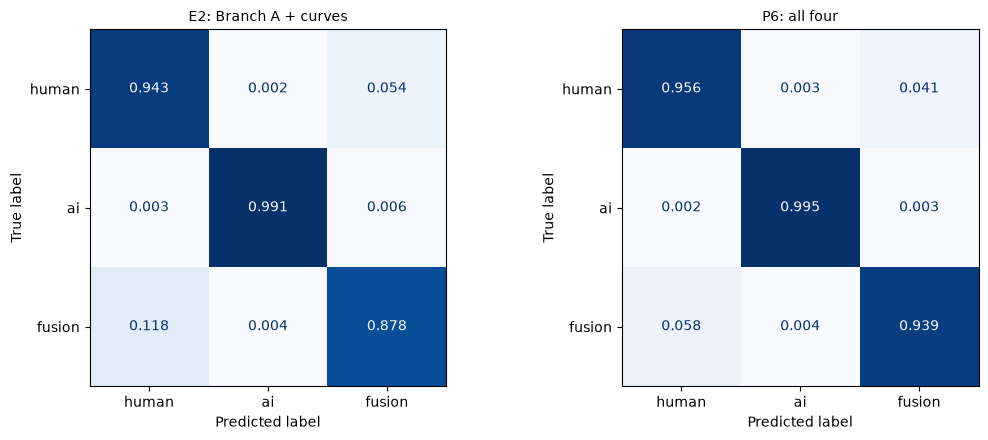

In [10]:
FINAL = max(best_runs, key=lambda name: best_runs[name]["cv_macro_f1"])
final_fit = fitted[FINAL]
print(f"final model: {FINAL} | {best_runs[FINAL]['model']} {best_runs[FINAL]['params']} | "
      f"class weights (human, fusion): {final_fit['weights']}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["E2: Branch A + curves", FINAL]):
    ConfusionMatrixDisplay.from_predictions(y["val"], fitted[name]["val_pred"], labels=LABELS, normalize="true",
                                            values_format=".3f", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
fig.tight_layout();

In [11]:
sample_submission = pd.read_csv(Path(kagglehub.competition_download(COMPETITION)) / "sample_submission.csv")
submission = make_submission(sets["test"]["id"], final_fit["test_pred"], sample_submission)
tag = FINAL.split(":")[0].lower()
SUBMISSION = Path("../submissions") / f"final_{tag}_{best_runs[FINAL]['model'].lower()}.csv"
submission.to_csv(SUBMISSION, index=False)
for set_name in ("val", "test"):
    pd.DataFrame(final_fit[f"{set_name}_probs"], columns=LABELS, index=X[set_name].index).to_csv(CACHE / f"final_probs_{set_name}.csv")
print(f"saved {SUBMISSION} ({len(submission):,} rows)")
pd.DataFrame({
    "val true %": pd.Series(y["val"]).value_counts(normalize=True),
    "val pred %": pd.Series(final_fit["val_pred"]).value_counts(normalize=True),
    "test pred %": pd.Series(final_fit["test_pred"]).value_counts(normalize=True),
    "test pred % (E2)": pd.Series(fitted["E2: Branch A + curves"]["test_pred"]).value_counts(normalize=True),
}).loc[LABELS].mul(100).round(1).T

saved ../submissions/final_p6_logreg.csv (25,000 rows)


,human,ai,fusion
val true %,24.5,44.8,30.7
val pred %,25.3,44.7,30.0
test pred %,25.6,51.3,23.0
test pred % (E2),26.8,51.0,22.2
